# Sensitivity Analysis: Correlated Proxy Disturbances

This notebook reads the aggregated CSV produced by `scripts/run_sensitivity_proxy_dependence.py` and plots sensitivity to correlated treatment- and outcome-proxy disturbances. The parameter $\rho$ is the latent Gaussian-copula correlation; the resulting proxies are used both structurally and observationally, so the intervention can violate the connected negative-control proxy assumption bundle.


In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS_CSV = Path("../results/sensitivity_proxy_dependence_copula_structural/results_metrics.csv")
OUTPUT_DIR = Path("pdfs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = [
    "PMMR",
    "Weighted PMMR",
    "KPV",
    "Weighted KPV",
    "DFPV",
    "Weighted DFPV",
]

MODEL_COLORS = {
    "PMMR": "#1f77b4",
    "Weighted PMMR": "#0d3b66",
    "KPV": "#2a9d8f",
    "Weighted KPV": "#0b6e4f",
    "DFPV": "#e76f51",
    "Weighted DFPV": "#9c2f1f",
}

MAIN_METRICS = [
    ("regret_causal_marginal", "Policy regret", "proxy_dependence_copula_structural_policy_regret"),
    ("global_rmse", "Counterfactual RMSE", "proxy_dependence_copula_structural_counterfactual_rmse"),
]

SECONDARY_METRICS = [
    ("local_rmse", "Local RMSE", "proxy_dependence_copula_structural_local_rmse"),
    ("mean_curve_rmse", "Mean curve RMSE", "proxy_dependence_copula_structural_mean_curve_rmse"),
]


In [8]:
df = pd.read_csv(RESULTS_CSV)
df = df[df["split"] == "test"].copy()
df = df[df["method"].isin(MODEL_ORDER)].copy()
df["violation_level"] = df["proxy_independence_violation_strength"].astype(float)
df = df.sort_values(["violation_level", "method", "seed"]).reset_index(drop=True)
print(df[["method", "seed", "violation_level"]].head())
print(f"Rows: {len(df)}")


  method  seed  violation_level
0   DFPV     1              0.0
1   DFPV     2              0.0
2   DFPV     3              0.0
3   DFPV     4              0.0
4   DFPV     5              0.0
Rows: 240


In [9]:
def summarize_metric(frame: pd.DataFrame, metric: str) -> pd.DataFrame:
    summary = (
        frame.groupby(["violation_level", "method"], as_index=False)[metric]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    summary["sem"] = summary["std"].fillna(0.0) / summary["count"].clip(lower=1) ** 0.5
    return summary


def plot_metric(frame: pd.DataFrame, metric: str, ylabel: str, save_stem: str) -> None:
    summary = summarize_metric(frame, metric)
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for method in MODEL_ORDER:
        part = summary[summary["method"] == method].copy()
        if part.empty:
            continue
        ax.plot(
            part["violation_level"],
            part["mean"],
            marker="o",
            linewidth=2,
            label=method,
            color=MODEL_COLORS[method],
        )
        ax.fill_between(
            part["violation_level"],
            part["mean"] - part["sem"],
            part["mean"] + part["sem"],
            alpha=0.18,
            color=MODEL_COLORS[method],
        )
    ax.set_xlabel("Gaussian-copula disturbance correlation rho")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(ncols=2, frameon=False)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{save_stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / f"{save_stem}.pdf", bbox_inches="tight")
    plt.show()


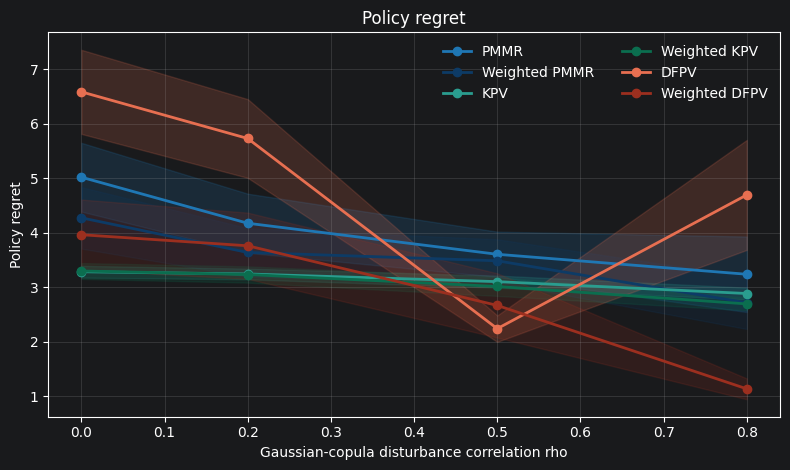

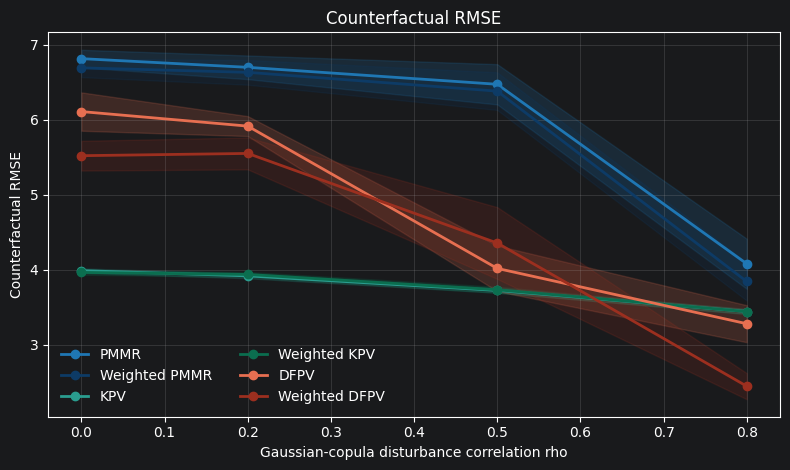

In [10]:
for metric_name, ylabel, save_stem in MAIN_METRICS:
    plot_metric(df, metric_name, ylabel, save_stem)


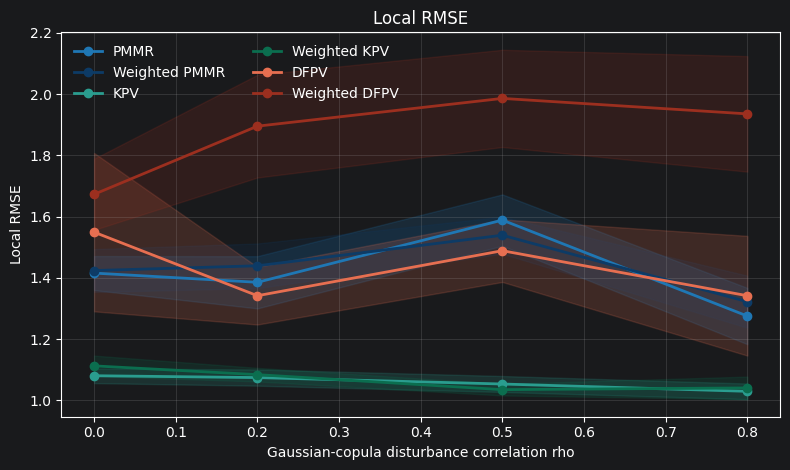

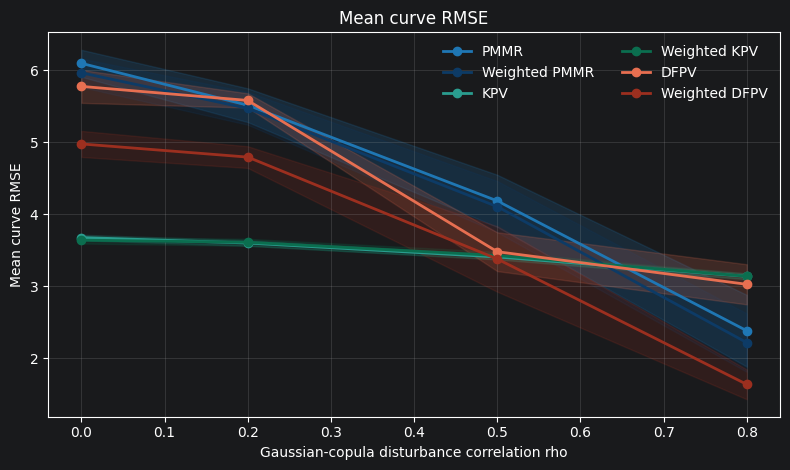

In [11]:
for metric_name, ylabel, save_stem in SECONDARY_METRICS:
    plot_metric(df, metric_name, ylabel, save_stem)


In [12]:
summary_table = (
    df.groupby(["method", "violation_level"], as_index=False)[["regret_causal_marginal", "global_rmse"]]
    .mean()
    .sort_values(["method", "violation_level"])
)
summary_table.head(20)


,method,violation_level,regret_causal_marginal,global_rmse
0,DFPV,0.0,6.586303,6.109998
1,DFPV,0.2,5.730753,5.915958
2,DFPV,0.5,2.241534,4.016162
3,DFPV,0.8,4.695304,3.277862
4,KPV,0.0,3.285946,3.986553
5,KPV,0.2,3.245005,3.916608
6,KPV,0.5,3.104496,3.721862
7,KPV,0.8,2.886406,3.440870
8,PMMR,0.0,5.020276,6.816526
9,PMMR,0.2,4.175770,6.700678
